# Practical 09 – Hierarchical Clustering with Dendrogram

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram


In [2]:
raw = load_iris(as_frame=True)
X = raw.data
scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
xy = pca.fit_transform(scaled)


In [3]:
def plot_clusters(labels, title, centers=None):
    plt.figure(figsize=(8, 5))
    plt.scatter(xy[:, 0], xy[:, 1], c=labels, cmap='viridis', s=40)
    if centers is not None:
        pc = pca.transform(centers)
        plt.scatter(pc[:, 0], pc[:, 1], marker='X', s=200, c='red', label='Centroids')
        plt.legend()
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title(title)
    plt.show()


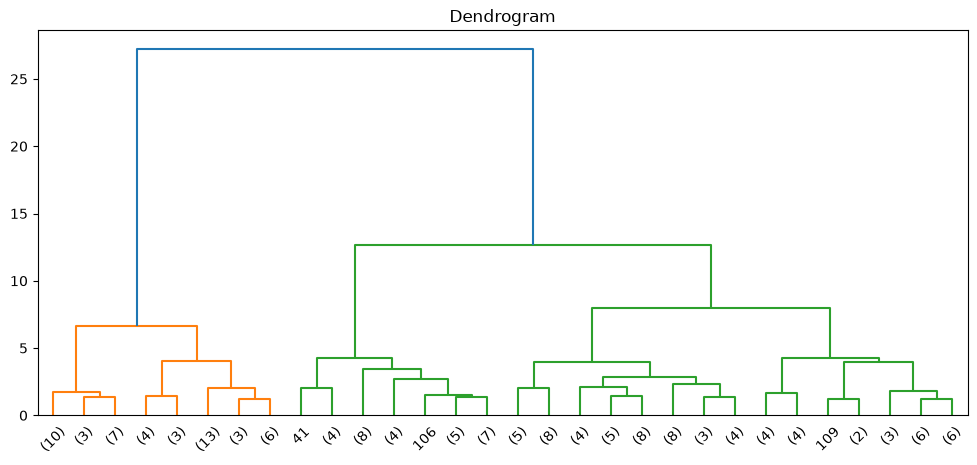

In [4]:
Z = linkage(scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrogram')
plt.show()
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = model.fit_predict(scaled)


Silhouette: 0.4466890410285909


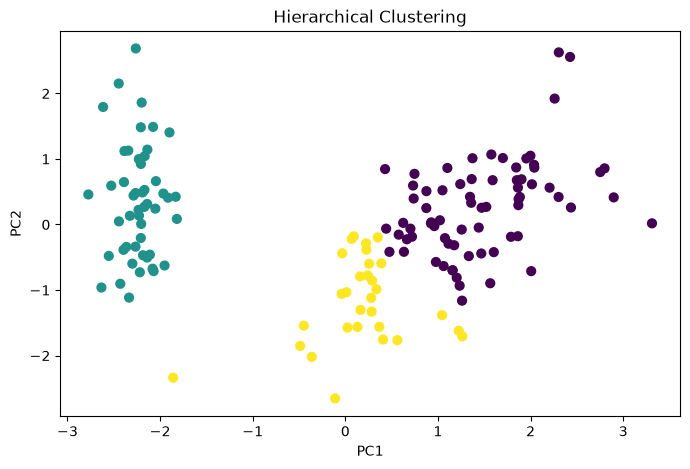

In [5]:
print('Silhouette:', silhouette_score(scaled, labels))
plot_clusters(labels, 'Hierarchical Clustering')
